In [1]:
import pandas as pd

df = pd.read_csv("annot/variant_table.tsv", sep="\t")
print(df.shape)
df.head(8)

(22, 8)


,pos,change,effect,impact,gene,DP,MQ,alt_frac
0,9972,T>G,missense_variant,MODERATE,yaaH,83,60,1.00
1,281923,G>T,upstream_gene_variant,MODIFIER,yagW,75,60,1.00
2,433359,CTTTTTTT>CTTTTTTTT,upstream_gene_variant,MODIFIER,insL-2,82,60,1.00
3,473901,CCGC>CCGCGC,frameshift_variant,HIGH,ybaL,72,60,0.99
4,648692,C>T,missense_variant,MODERATE,mrdB,92,60,1.00
5,1331794,C>A,missense_variant,MODERATE,topA,53,60,1.00
6,1733343,G>A,missense_variant,MODERATE,pykF,94,60,1.00
7,2103887,long>long,disruptive_inframe_insertion,MODERATE,ECB_01992,28,60,0.86


effect
missense_variant                12
upstream_gene_variant            5
frameshift_variant               3
disruptive_inframe_insertion     1
downstream_gene_variant          1
Name: count, dtype: int64


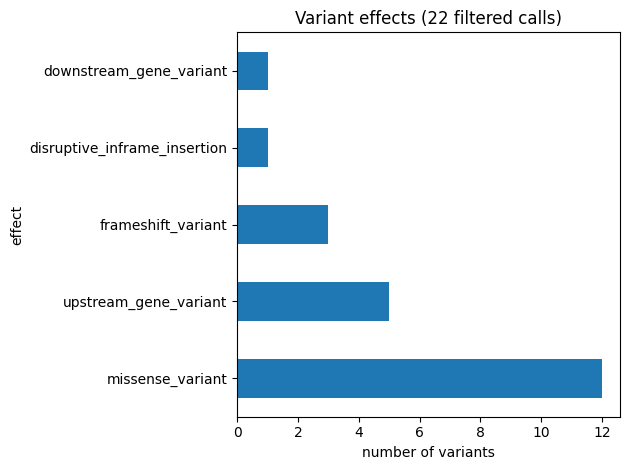

In [2]:
import matplotlib.pyplot as plt

counts = df["effect"].value_counts()
print(counts)

counts.plot(kind="barh")
plt.xlabel("number of variants")
plt.title("Variant effects (22 filtered calls)")
plt.tight_layout()
plt.show()

         gene  DP  alt_frac igv_verdict low_depth
16       yieO  16      1.00    artifact       yes
7   ECB_01992  28      0.86    probable       yes
5        topA  53      1.00   unchecked        no
15       glpR  61      1.00   unchecked        no
14       malT  71      1.00   unchecked        no


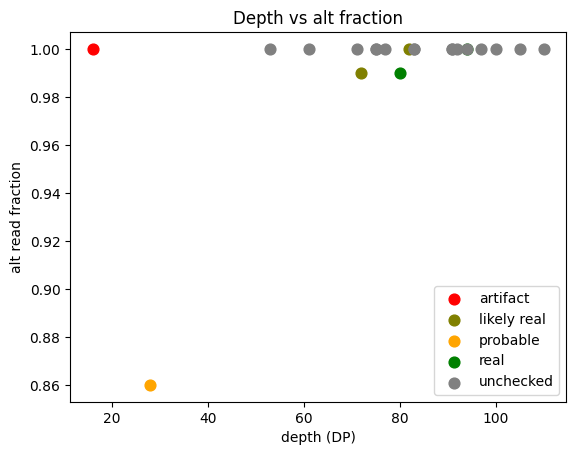

In [3]:
import numpy as np

verdicts = {"pykF": "real", "elaC": "real", "ybaL": "likely real",
            "insL-2": "likely real", "ECB_01992": "probable", "yieO": "artifact"}
df["igv_verdict"] = df["gene"].map(verdicts).fillna("unchecked")
df["low_depth"] = np.where(df["DP"] < 30, "yes", "no")

print(df[["gene", "DP", "alt_frac", "igv_verdict", "low_depth"]].sort_values("DP").head(5))

colors = {"real": "green", "likely real": "olive", "probable": "orange",
          "artifact": "red", "unchecked": "gray"}
for v, sub in df.groupby("igv_verdict"):
    plt.scatter(sub["DP"], sub["alt_frac"], c=colors[v], label=v, s=60)
plt.xlabel("depth (DP)")
plt.ylabel("alt read fraction")
plt.legend()
plt.title("Depth vs alt fraction")
plt.show()

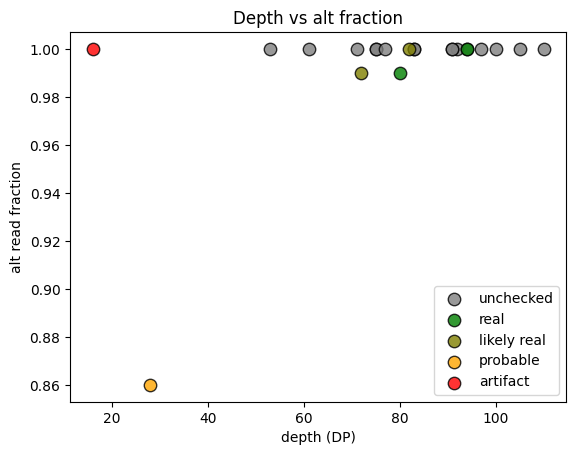

        pos  gene  DP  igv_verdict
3    473901  ybaL  72  likely real
16  3901455  yieO  16     artifact
20  4431393  ytfN  77    unchecked


In [4]:
order = ["unchecked", "real", "likely real", "probable", "artifact"]
for v in order:
    sub = df[df["igv_verdict"] == v]
    plt.scatter(sub["DP"], sub["alt_frac"], c=colors[v], label=v,
                s=80, alpha=0.8, edgecolors="black")
plt.xlabel("depth (DP)")
plt.ylabel("alt read fraction")
plt.legend()
plt.title("Depth vs alt fraction")
plt.savefig("annot/depth_vs_altfrac.png", dpi=150, bbox_inches="tight")
plt.show()

high = df[df["impact"] == "HIGH"]
print(high[["pos", "gene", "DP", "igv_verdict"]])

In [5]:
final = df[df["igv_verdict"] != "artifact"]
final.to_csv("annot/final_calls_with_verdicts.csv", index=False)

print(len(final))
print(final.groupby("impact").size())

21
impact
HIGH         2
MODERATE    13
MODIFIER     6
dtype: int64


In [6]:
verdicts["ytfN"] = "real"
df["igv_verdict"] = df["gene"].map(verdicts).fillna("unchecked")

final = df[df["igv_verdict"] != "artifact"]
final.to_csv("annot/final_calls_with_verdicts.csv", index=False)
print(final["igv_verdict"].value_counts())

igv_verdict
unchecked      15
real            3
likely real     2
probable        1
Name: count, dtype: int64


In [7]:
for g in ["ytfN", "topA", "fis", "malT", "mrdB"]:
    verdicts[g] = "real"
df["igv_verdict"] = df["gene"].map(verdicts).fillna("unchecked")

final = df[df["igv_verdict"] != "artifact"]
final.to_csv("annot/final_calls_with_verdicts.csv", index=False)
print(final["igv_verdict"].value_counts())

igv_verdict
unchecked      11
real            7
likely real     2
probable        1
Name: count, dtype: int64
